In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ast

# Set the default Seaborn theme
sns.set_theme(style="ticks")

# Load the dataset and parse dates
df = pd.read_csv("../data_jobs.csv", parse_dates=["job_posted_date"])

# Convert string representations of lists into actual Python lists
df["job_skills"] = df["job_skills"].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

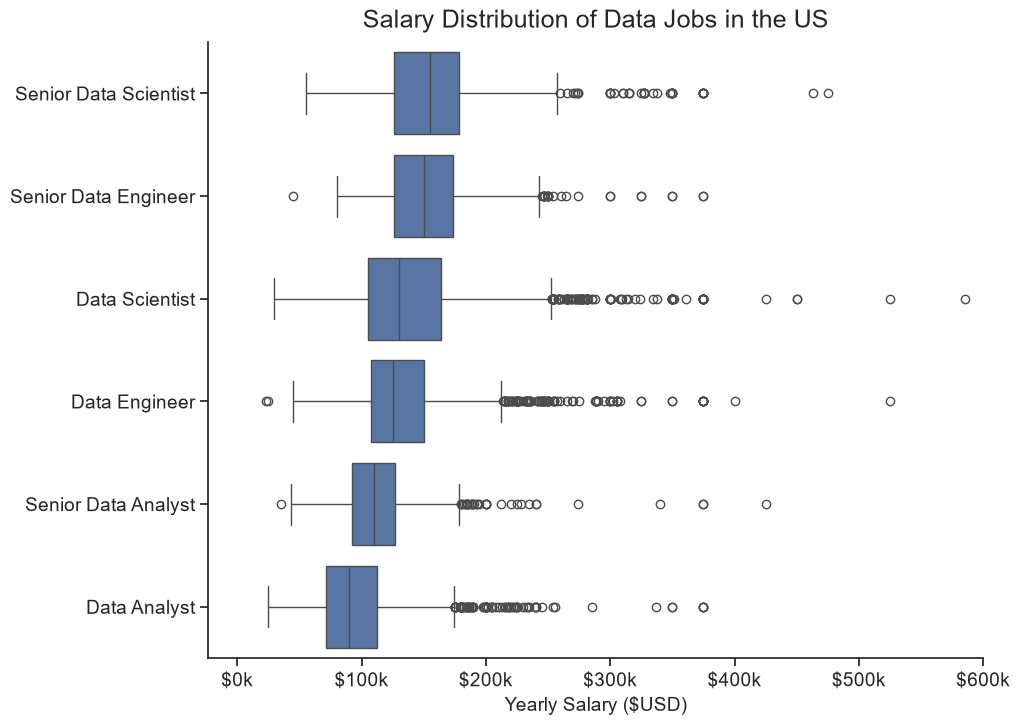

In [4]:
job_titles = [
    "Senior Data Scientist",
    "Senior Data Engineer",
    "Senior Data Analyst",
    "Data Scientist",
    "Data Engineer",
    "Data Analyst",
]

# Filter US jobs with available yearly salary data for the selected roles
df_US = df[(df["job_country"] == "United States")&(df['job_title_short'].isin(job_titles))].dropna(subset="salary_year_avg")

# Sort the Jobs Titles by Median salary
top_median_salary = df_US.groupby('job_title_short')['salary_year_avg'].median().sort_values(ascending=False).index

plt.figure(figsize=(10, 8))

# Compare salary distributions while keeping job titles in the specified order
sns.boxplot(df_US, x='salary_year_avg', y='job_title_short', order=top_median_salary)

# Limit the displayed salary range to improve readability
plt.xlim(right=600_000)

# Format salary ticks in thousands (e.g., $100k)
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x,_: f"${x/1000:.0f}k")) # type: ignore

plt.title('Salary Distribution of Data Jobs in the US', fontsize=18, y=1.01)
plt.xlabel('Yearly Salary ($USD)', fontsize=14)
plt.ylabel('')
plt.tick_params(labelsize=14)

# Remove the top and right spines for a cleaner appearance
sns.despine()
plt.show()

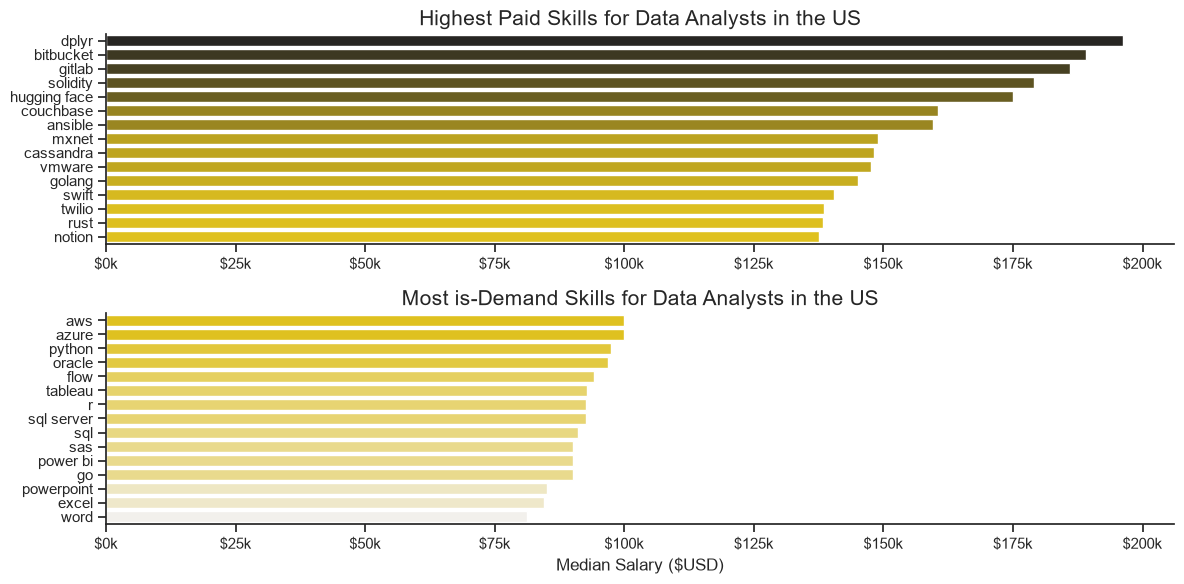

In [ ]:
# Expand each job's skills into separate rows and exclude missing salary data
df_explode = df.explode('job_skills').dropna(subset='salary_year_avg')

# Filter for US Data Analyst positions
df_DA_US = df_explode[(df_explode['job_title_short'] == 'Data Analyst') & (df_explode['job_country'] == 'United States')]

# Calculate median salary and number of job postings for each skill
df_skills = df_DA_US.groupby("job_skills", as_index=False).agg(median_salary=('salary_year_avg', 'median'), count=('job_skills', 'count'))

# Select the 15 highest-paying skills
top_payed_skills = df_skills.sort_values(by='median_salary', ascending=False).head(15)

# Select the 15 most demanded skills and rank them by median salary
top_demanded_skills = (
    df_skills
    .sort_values(by="count", ascending=False)
    .head(15)
    .sort_values(by="median_salary", ascending=False)
)

# Create two vertically stacked plots for comparison
fig, ax = plt.subplots(2, 1, figsize=(12, 6))

# Plot the highest-paying skills
sns.barplot(
    top_payed_skills,
    x="median_salary",
    y="job_skills",
    ax=ax[0],
    hue="median_salary",
    palette="dark:gold_r",
    legend=False,
)

# Plot the most demanded skills, ordered by median salary
sns.barplot(
    top_demanded_skills,
    x="median_salary",
    y="job_skills",
    ax=ax[1],
    hue="median_salary",
    palette='light:gold',
    legend=False
)

# Use the same salary scale in both plots for a fair comparison
ax[1].set_xlim(ax[0].get_xlim())

# Format salary ticks in thousands (e.g., $100k)
ax[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x,_: f"${x/1000:.0f}k")) # type: ignore
ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x,_: f"${x/1000:.0f}k")) # type: ignore

ax[0].set_title("Highest Paid Skills for Data Analysts in the US", fontsize=15)
ax[1].set_title('Most is-Demand Skills for Data Analysts in the US', fontsize=15)

# Keep the charts focused on the skill labels and salary values
ax[0].set_ylabel('')
ax[1].set_ylabel('')
ax[0].set_xlabel('')
ax[1].set_xlabel('Median Salary ($USD)')

fig.tight_layout()
sns.despine()
plt.show()